# 02 · Generate reasoning paths

**Purpose**
- Run BLIP-2 once per question and save everything to a cache file.
- Every method in notebooks 03–05 reads this cache → fair comparison, no GPU needed later.

**Per question**
- **Greedy answer**: standard BLIP-2 (baseline)
- **k = 10 paths**: sampled evidence sentence → answer
- **Answer confidence**: mean log-probability of the answer tokens
- **Grounding confidence**: BLIP-2 image-text matching score of the evidence

**Runtime:** GPU → **L4**. Full run ≈ 1.5–3 h. Resumable: if Colab disconnects, rerun Steps 1–4 and the run continues where it stopped.

## 1 · Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.utils import load_config, set_seed, gpu_info
from src.errorlog import log_error
from src.gitsync import save_and_push

cfg = load_config()
set_seed(cfg["seed"])
SEED, GEN = cfg["seed"], cfg["generation"]
DATA, CACHE = cfg["paths"]["data"], cfg["paths"]["cache"]
print(gpu_info())
print("Generation settings:", GEN)

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr
NVIDIA L4 | 23.7 GB | torch 2.11.0+cu130
Generation settings: {'k': 10, 'temperature': 0.7, 'top_p': 0.9, 'max_new_tokens': 40}


## 2 · Path-generation code
- Writes `src/paths.py`, reused by later notebooks.
- Two evidence prompts × 5 samples = 10 paths; answers are then decoded greedily **given** each evidence sentence.
- Log-probabilities use the raw logits, so they reflect the model's confidence, not the sampler's temperature.
- BLIP-2 runs in bfloat16 (T5 overflows in float16).

In [2]:
%%writefile src/paths.py
"""BLIP-2 multi-path generation and confidence scoring.

Written from notebooks/02_generate_paths.ipynb; the output cache is read by notebooks 03-05.

For each question we store:
- greedy:  the standard single BLIP-2 answer (baseline)
- paths:   k reasoning paths = sampled evidence sentence -> answer, each with
           answer confidence (token log-probabilities) and
           grounding confidence (BLIP-2 image-text matching on the evidence)
"""

import json
import os
import re
import time
import zlib

import torch
from PIL import Image

EVIDENCE_PROMPTS = [
    "Question: {q} Describe the objects in the image that are needed to answer this question.",
    "Question: {q} Briefly describe the part of the image this question is about.",
]
ANSWER_PROMPT = "Context: {e} Question: {q} Short answer:"
GREEDY_PROMPT = "Question: {q} Short answer:"   # BLIP-2 paper's zero-shot VQA prompt


# ---------------------------------------------------------------- models
def _dtype_kw(dtype):
    """transformers >= 4.56 uses `dtype`, older versions `torch_dtype`."""
    import transformers
    from packaging.version import Version
    new = Version(transformers.__version__) >= Version("4.56")
    return {"dtype": dtype} if new else {"torch_dtype": dtype}


def load_models(vqa_id: str, itm_id: str, device: str = "cuda"):
    """BLIP-2 FlanT5-XL for generation (bf16: avoids T5 fp16 overflow) and the ITM model (fp16)."""
    from transformers import AutoProcessor, Blip2ForConditionalGeneration, Blip2ForImageTextRetrieval
    vqa_proc = AutoProcessor.from_pretrained(vqa_id)
    vqa = Blip2ForConditionalGeneration.from_pretrained(vqa_id, **_dtype_kw(torch.bfloat16)).to(device).eval()
    itm_proc = AutoProcessor.from_pretrained(itm_id)
    itm = Blip2ForImageTextRetrieval.from_pretrained(itm_id, **_dtype_kw(torch.float16)).to(device).eval()
    return vqa_proc, vqa, itm_proc, itm


# ---------------------------------------------------------------- generation
@torch.no_grad()
def generate(proc, model, image, prompts, n_per_prompt=1, sample=False,
             max_new_tokens=10, temperature=0.7, top_p=0.9):
    """Generate text for each prompt on one image; return text + token log-probabilities.

    Log-probabilities come from the raw logits (before temperature / top-p),
    so they measure the model's own confidence, not the sampler's.
    """
    inputs = proc(images=[image] * len(prompts), text=prompts, return_tensors="pt", padding=True).to(model.device)
    inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)
    kw = dict(max_new_tokens=max_new_tokens, num_return_sequences=n_per_prompt,
              return_dict_in_generate=True, output_logits=True)
    kw.update(dict(do_sample=True, temperature=temperature, top_p=top_p) if sample else dict(do_sample=False))
    out = model.generate(**inputs, **kw)

    seqs = out.sequences[:, 1:]                                   # drop T5 decoder-start token
    logits = torch.stack(out.logits, dim=1).float()               # (batch, steps, vocab)
    lp = logits.log_softmax(-1).gather(-1, seqs.unsqueeze(-1)).squeeze(-1)
    eos = model.generation_config.eos_token_id
    is_eos = torch.isin(seqs, torch.tensor(eos if isinstance(eos, list) else [eos], device=seqs.device))
    mask = (is_eos.cumsum(1) - is_eos.long()) == 0                # tokens up to and including the first end token
    n_tok = mask.sum(1).clamp(min=1)
    lp_sum = (lp * mask).sum(1)
    texts = proc.batch_decode(seqs, skip_special_tokens=True)
    return [
        {"text": t.strip(), "lp_sum": s.item(), "lp_mean": (s / n).item(), "n_tok": int(n)}
        for t, s, n in zip(texts, lp_sum, n_tok)
    ]


@torch.no_grad()
def grounding(proc, model, image, texts):
    """Grounding confidence of each text against the image.

    itm: P(match) from BLIP-2's image-text matching head (main signal)
    itc: image-text cosine similarity (cheaper alternative, kept for ablation)
    """
    texts = [t if t.strip() else "nothing" for t in texts]
    # tokenizer and image processor called separately: the ITM text encoder (BERT) takes
    # plain text, so no image placeholder tokens are inserted
    inputs = dict(proc.tokenizer(texts, padding=True, truncation=True, max_length=64, return_tensors="pt"))
    inputs["pixel_values"] = proc.image_processor([image] * len(texts), return_tensors="pt")["pixel_values"]
    inputs = {k: v.to(model.device) for k, v in inputs.items() if k in ("input_ids", "attention_mask", "pixel_values")}
    inputs["pixel_values"] = inputs["pixel_values"].to(model.dtype)
    itm = model(**inputs, use_image_text_matching_head=True).logits_per_image.float().softmax(-1)[:, 1]
    itc = model(**inputs, use_image_text_matching_head=False).logits_per_image.float()
    itc = itc.diagonal() if itc.dim() == 2 else itc
    return itm.tolist(), itc.tolist()


def process_question(models, image, question, k_per_prompt=5, temperature=0.7, top_p=0.9, ev_tokens=40):
    """Greedy answer + k reasoning paths with both confidence signals, for one question."""
    vqa_proc, vqa, itm_proc, itm = models
    greedy = generate(vqa_proc, vqa, image, [GREEDY_PROMPT.format(q=question)])[0]

    ev = generate(vqa_proc, vqa, image, [p.format(q=question) for p in EVIDENCE_PROMPTS],
                  n_per_prompt=k_per_prompt, sample=True, max_new_tokens=ev_tokens,
                  temperature=temperature, top_p=top_p)
    ans = generate(vqa_proc, vqa, image, [ANSWER_PROMPT.format(e=e["text"], q=question) for e in ev])
    itm_s, itc_s = grounding(itm_proc, itm, image, [e["text"] for e in ev])

    paths = [{
        "template": j // k_per_prompt,
        "evidence": e["text"], "ev_lp_mean": e["lp_mean"],
        "answer": a["text"], "lp_mean": a["lp_mean"], "lp_sum": a["lp_sum"], "n_tok": a["n_tok"],
        "itm": g, "itc": c,
    } for j, (e, a, g, c) in enumerate(zip(ev, ans, itm_s, itc_s))]
    return {"greedy": {"answer": greedy["text"], "lp_mean": greedy["lp_mean"], "lp_sum": greedy["lp_sum"]},
            "paths": paths}


# ---------------------------------------------------------------- cache
def read_cache(path: str) -> list[dict]:
    """Read a JSONL cache, skipping a half-written last line after a crash."""
    if not os.path.exists(path):
        return []
    recs = []
    with open(path) as f:
        for line in f:
            try:
                recs.append(json.loads(line))
            except json.JSONDecodeError:
                pass
    return recs


def run(df, image_dir: str, out_path: str, models, k: int = 10, temperature=0.7, top_p=0.9,
        seed: int = 42, ev_tokens: int = 40, log_every: int = 25, limit: int | None = None):
    """Process every question in df, appending one JSON line each to out_path.

    Resumable: questions already in out_path are skipped, so a disconnect loses nothing.
    """
    done = {r["id"] for r in read_cache(out_path)}
    todo = df[~df["id"].isin(done)]
    if limit:
        todo = todo.head(limit)
    print(f"{len(done)} done, {len(todo)} to go -> {out_path}")
    k_per_prompt = k // len(EVIDENCE_PROMPTS)

    t0 = time.time()
    with open(out_path, "a") as f:
        for i, r in enumerate(todo.itertuples(index=False), 1):
            torch.manual_seed(seed + zlib.crc32(r.id.encode()))   # same paths on every re-run
            image = Image.open(f"{image_dir}/{r.imageId}.jpg").convert("RGB")
            rec = {"id": r.id, **process_question(models, image, r.question, k_per_prompt,
                                                  temperature, top_p, ev_tokens)}
            f.write(json.dumps(rec) + "\n")
            f.flush()
            if i % log_every == 0 or i == len(todo):
                rate = (time.time() - t0) / i
                print(f"  {i}/{len(todo)}  {rate:.2f} s/question  ETA {rate * (len(todo) - i) / 60:.0f} min")


# ---------------------------------------------------------------- answers
_ARTICLES = re.compile(r"\b(a|an|the)\b")
_PUNCT = re.compile(r"[^\w\s]")


def normalize(ans: str) -> str:
    """Lower-case, drop punctuation and articles, squeeze spaces (GQA uses exact match)."""
    ans = _PUNCT.sub(" ", ans.lower())
    ans = _ARTICLES.sub(" ", ans)
    return " ".join(ans.split())

Writing src/paths.py


In [3]:
import importlib, os, json, gzip, shutil
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
import src.paths as P
importlib.reload(P)

TEST_C, VAL_C, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

## 3 · Load the samples from notebook 01
- IDs are read as text so they match the cache exactly.

In [4]:
read = lambda f: pd.read_csv(f, dtype={"id": str, "imageId": str})
eval_df, calib_df = read("data/eval_testdev.csv"), read("data/calib_val.csv")
IMG = {"eval": f"{DATA}/images/testdev", "calib": f"{DATA}/images/val"}
OUT = {"eval": f"{CACHE}/paths_eval.jsonl", "calib": f"{CACHE}/paths_calib.jsonl"}
print(f"eval {len(eval_df):,} | calib {len(calib_df):,}")

eval 2,500 | calib 500


## 4 · Load the models
- BLIP-2 FlanT5-XL (~4B parameters) for answers; BLIP-2 ITM (~1B) for grounding.
- First run downloads ~17 GB of weights (≈5–10 min); fits easily in the L4's 24 GB.

In [5]:
models = P.load_models(cfg["models"]["vqa"], cfg["models"]["itm"])
print(f"GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/21.0k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

... (13 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.69GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/809 [00:00<?, ?it/s]

GPU memory used: 10.6 GB


## 5 · One question, step by step
- Shows exactly what is stored per path.
- Good example figure for the Method section of the report.

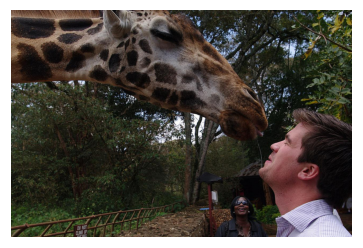

Q: The giraffe is in front of what?
Gold: forest
Greedy: a man


,evidence,answer,lp_mean,itm
0,"man, tree, giraffe",a tree,-0.319,0.776
1,man,a man,-0.424,0.379
2,a man,a man,-0.401,0.362
3,a man,a man,-0.401,0.362
4,a man,a man,-0.401,0.362
5,a man,a man,-0.401,0.362
6,a man,a man,-0.401,0.362
7,a man,a man,-0.401,0.362
8,a man,a man,-0.401,0.362
9,a tree,a tree,-0.242,0.373


In [6]:
r = eval_df.iloc[0]
image = Image.open(f"{IMG['eval']}/{r.imageId}.jpg").convert("RGB")
torch.manual_seed(SEED)
demo = P.process_question(models, image, r.question, k_per_prompt=GEN["k"] // len(P.EVIDENCE_PROMPTS),
                          temperature=GEN["temperature"], top_p=GEN["top_p"], ev_tokens=GEN["max_new_tokens"])

plt.figure(figsize=(4, 4)); plt.imshow(image); plt.axis("off"); plt.show()
print(f"Q: {r.question}\nGold: {r.answer}\nGreedy: {demo['greedy']['answer']}")
pd.set_option("display.max_colwidth", 80)
pd.DataFrame(demo["paths"])[["evidence", "answer", "lp_mean", "itm"]].round(3)

## 6 · Pilot: 30 questions
- Checks speed and that the outputs make sense **before** the long run.
- Accuracy here is rough (30 questions); it only needs to be plausible.
- Reference: BLIP-2 FlanT5-XL zero-shot GQA ≈ 44% (Li et al., 2023).
- **Go on** if greedy accuracy is roughly 35–50% and "any path correct" (oracle) is clearly above it.

In [7]:
def quick_stats(recs, df):
    gold = dict(zip(df.id, df.answer.map(P.normalize)))
    g = m = o = 0
    for rec in recs:
        y = gold[rec["id"]]
        answers = [P.normalize(p["answer"]) for p in rec["paths"]]
        g += P.normalize(rec["greedy"]["answer"]) == y
        m += Counter(answers).most_common(1)[0][0] == y
        o += y in answers
    n = len(recs)
    return pd.Series({"questions": n, "greedy acc": g / n, "majority-vote acc": m / n,
                      "oracle (any path correct)": o / n,
                      "distinct answers per question": np.mean([len({P.normalize(p['answer']) for p in r['paths']}) for r in recs])}).round(3)

PILOT = f"{CACHE}/pilot.jsonl"
if os.path.exists(PILOT):
    os.remove(PILOT)                      # pilot always starts fresh
P.run(calib_df, IMG["calib"], PILOT, models, k=GEN["k"], temperature=GEN["temperature"],
      top_p=GEN["top_p"], seed=SEED, ev_tokens=GEN["max_new_tokens"], log_every=10, limit=30)
quick_stats(P.read_cache(PILOT), calib_df)

0 done, 30 to go -> /content/drive/MyDrive/cw-mpvr-data/cache/pilot.jsonl
  10/30  1.91 s/question  ETA 1 min
  20/30  1.88 s/question  ETA 0 min
  30/30  1.87 s/question  ETA 0 min


,0
questions,30.000
greedy acc,0.567
majority-vote acc,0.500
oracle (any path correct),0.767
distinct answers per question,2.033


In [8]:
# Pilot B: more diverse sampling, same 30 questions
PILOT_B = f"{CACHE}/pilot_t1.jsonl"
if os.path.exists(PILOT_B):
    os.remove(PILOT_B)
P.run(calib_df, IMG["calib"], PILOT_B, models, k=GEN["k"], temperature=1.0, top_p=0.95,
      seed=SEED, ev_tokens=GEN["max_new_tokens"], log_every=10, limit=30)

def ev_words(recs):
    return np.mean([len(p["evidence"].split()) for r in recs for p in r["paths"]])

cmp = pd.DataFrame({"T=0.7, p=0.9":  quick_stats(P.read_cache(PILOT), calib_df),
                    "T=1.0, p=0.95": quick_stats(P.read_cache(PILOT_B), calib_df)})
cmp.loc["evidence words"] = [ev_words(P.read_cache(PILOT)), ev_words(P.read_cache(PILOT_B))]
cmp.round(3)

0 done, 30 to go -> /content/drive/MyDrive/cw-mpvr-data/cache/pilot_t1.jsonl
  10/30  1.32 s/question  ETA 0 min
  20/30  1.31 s/question  ETA 0 min
  30/30  1.35 s/question  ETA 0 min


,"T=0.7, p=0.9","T=1.0, p=0.95"
questions,30.000,30.000
greedy acc,0.567,0.567
majority-vote acc,0.500,0.467
oracle (any path correct),0.767,0.833
distinct answers per question,2.033,2.400
evidence words,2.607,3.413


In [9]:
import re

# 1. save new sampling settings to the config (keeps runs reproducible)
p = "configs/default.yaml"
s = open(p).read()
s = re.sub(r"temperature: [\d.]+", "temperature: 1.0", s)
s = re.sub(r"top_p: [\d.]+", "top_p: 0.95", s)
open(p, "w").write(s)
cfg = load_config(); GEN = cfg["generation"]
print("Generation settings:", GEN)

# 2. record the issue
log_error(
    where="02_generate_paths / step 6 (pilot, 30 calibration questions)",
    error="Low path diversity: 7 of 10 evidence sentences identical; 2.0 distinct answers per question; majority vote below greedy",
    cause="Sampling at temperature 0.7, top-p 0.9 is too conservative for FlanT5, which favours very short outputs (mode collapse)",
    fix="Raised to temperature 1.0, top-p 0.95 (tuned on calibration questions only): oracle 76.7% -> 83.3%, distinct answers 2.0 -> 2.4",
    lesson="Check path diversity before a long run; evidence remains short (~3 words), noted as a limitation",
)

Generation settings: {'k': 10, 'temperature': 1.0, 'top_p': 0.95, 'max_new_tokens': 40}
Logged as E02:
### E02 (2026-10-25)
- **Where**: 02_generate_paths / step 6 (pilot, 30 calibration questions)
- **Error**: `Low path diversity: 7 of 10 evidence sentences identical; 2.0 distinct answers per question; majority vote below greedy`
- **Cause**: Sampling at temperature 0.7, top-p 0.9 is too conservative for FlanT5, which favours very short outputs (mode collapse)
- **Fix**: Raised to temperature 1.0, top-p 0.95 (tuned on calibration questions only): oracle 76.7% -> 83.3%, distinct answers 2.0 -> 2.4
- **Lesson**: Check path diversity before a long run; evidence remains short (~3 words), noted as a limitation



## 7 · Full run: calibration set (500)
- ≈ 15–30 min. Progress and ETA print every 25 questions.

In [10]:
P.run(calib_df, IMG["calib"], OUT["calib"], models, k=GEN["k"], temperature=GEN["temperature"],
      top_p=GEN["top_p"], seed=SEED, ev_tokens=GEN["max_new_tokens"])

0 done, 500 to go -> /content/drive/MyDrive/cw-mpvr-data/cache/paths_calib.jsonl
  25/500  1.32 s/question  ETA 10 min
  50/500  1.60 s/question  ETA 12 min
  75/500  1.75 s/question  ETA 12 min
  100/500  1.81 s/question  ETA 12 min
  125/500  1.87 s/question  ETA 12 min
  150/500  1.90 s/question  ETA 11 min
  175/500  1.91 s/question  ETA 10 min
  200/500  1.93 s/question  ETA 10 min
  225/500  1.94 s/question  ETA 9 min
  250/500  1.96 s/question  ETA 8 min
  275/500  1.97 s/question  ETA 7 min
  300/500  1.98 s/question  ETA 7 min
  325/500  1.98 s/question  ETA 6 min
  350/500  1.98 s/question  ETA 5 min
  375/500  1.99 s/question  ETA 4 min
  400/500  2.00 s/question  ETA 3 min
  425/500  2.00 s/question  ETA 3 min
  450/500  2.00 s/question  ETA 2 min
  475/500  2.01 s/question  ETA 1 min
  500/500  2.01 s/question  ETA 0 min


## 8 · Full run: evaluation set (2,500)
- ≈ 1.5–2.5 h. Keep the tab open.
- If Colab disconnects: rerun Steps 1, 2, 3, 4, then this cell; it skips finished questions.

In [11]:
P.run(eval_df, IMG["eval"], OUT["eval"], models, k=GEN["k"], temperature=GEN["temperature"],
      top_p=GEN["top_p"], seed=SEED, ev_tokens=GEN["max_new_tokens"])

0 done, 2500 to go -> /content/drive/MyDrive/cw-mpvr-data/cache/paths_eval.jsonl
  25/2500  2.13 s/question  ETA 88 min
  50/2500  2.08 s/question  ETA 85 min
  75/2500  2.04 s/question  ETA 83 min
  100/2500  2.06 s/question  ETA 82 min
  125/2500  2.04 s/question  ETA 81 min
  150/2500  2.03 s/question  ETA 79 min
  175/2500  2.02 s/question  ETA 78 min
  200/2500  2.00 s/question  ETA 77 min
  225/2500  1.99 s/question  ETA 75 min
  250/2500  1.97 s/question  ETA 74 min
  275/2500  1.96 s/question  ETA 73 min
  300/2500  1.95 s/question  ETA 72 min
  325/2500  1.94 s/question  ETA 70 min
  350/2500  1.92 s/question  ETA 69 min
  375/2500  1.90 s/question  ETA 67 min
  400/2500  1.90 s/question  ETA 66 min
  425/2500  1.88 s/question  ETA 65 min
  450/2500  1.87 s/question  ETA 64 min
  475/2500  1.86 s/question  ETA 63 min
  500/2500  1.85 s/question  ETA 62 min
  525/2500  1.84 s/question  ETA 61 min
  550/2500  1.83 s/question  ETA 59 min
  575/2500  1.83 s/question  ETA 59 min
  

## 9 · Sanity check on the full cache
- Same quick numbers as the pilot, now on all questions.
- Not the final results: proper aggregation and statistics come in notebooks 03–05.

In [12]:
recs = {s: P.read_cache(OUT[s]) for s in OUT}
stats = pd.DataFrame({"eval": quick_stats(recs["eval"], eval_df), "calib": quick_stats(recs["calib"], calib_df)})
stats.to_csv("results/02_sanity.csv")
stats

,eval,calib
questions,2500.000,500.000
greedy acc,0.402,0.434
majority-vote acc,0.407,0.416
oracle (any path correct),0.598,0.644
distinct answers per question,2.631,2.598


## 10 · Do the two signals predict correctness?
- Every path, split into 10 equal-size groups by each signal.
- If a line rises from left to right, that signal separates right from wrong paths.
- First evidence for the core idea; tested properly in notebook 05.

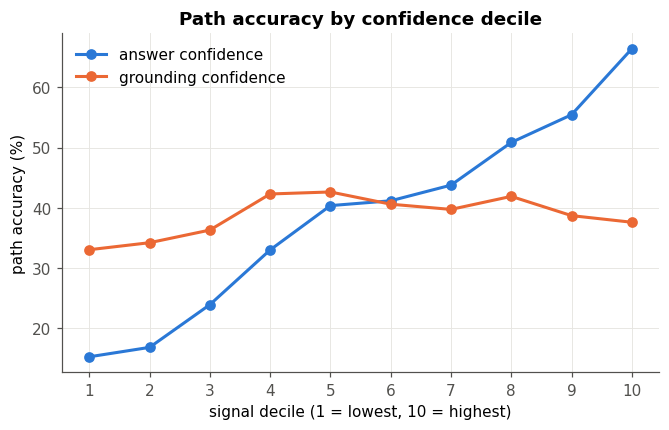

30,000 paths | Spearman(answer conf, grounding conf) = -0.10


In [13]:
gold = dict(zip(calib_df.id, calib_df.answer.map(P.normalize)))
gold.update(zip(eval_df.id, eval_df.answer.map(P.normalize)))
rows = [{"lp_mean": p["lp_mean"], "itm": p["itm"],
         "correct": P.normalize(p["answer"]) == gold[r["id"]]}
        for s in recs for r in recs[s] for p in r["paths"]]
pp = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(7, 4))
for col, c, name in [("lp_mean", TEST_C, "answer confidence"), ("itm", VAL_C, "grounding confidence")]:
    dec = pd.qcut(pp[col].rank(method="first"), 10, labels=False) + 1
    acc = pp.groupby(dec).correct.mean() * 100
    ax.plot(acc.index, acc.values, "-o", color=c, linewidth=2, markersize=6, label=name)
ax.set_xticks(range(1, 11))
ax.set_xlabel("signal decile (1 = lowest, 10 = highest)"); ax.set_ylabel("path accuracy (%)")
ax.set_title("Path accuracy by confidence decile"); ax.legend()
plt.savefig("figures/02_signal_deciles.png"); plt.show()
print(f"{len(pp):,} paths | Spearman(answer conf, grounding conf) = {pp[['lp_mean','itm']].corr('spearman').iloc[0,1]:.2f}")

## 11 · Keep a copy of the cache in the repo
- Compressed copies go to `results/` (a few MB) so anyone can reproduce notebooks 03–05 **without a GPU**.

In [14]:
for s, path in OUT.items():
    dst = f"results/paths_{s}.jsonl.gz"
    with open(path, "rb") as fi, gzip.open(dst, "wb") as fo:
        shutil.copyfileobj(fi, fo)
    print(f"{dst}: {os.path.getsize(dst) / 1e6:.1f} MB")

results/paths_eval.jsonl.gz: 1.4 MB
results/paths_calib.jsonl.gz: 0.3 MB


In [15]:
# 10b · Within-question test: among the paths for ONE question, do correct paths score higher?
from scipy.stats import wilcoxon

SIGNALS = {"lp_mean": "answer confidence", "itm": "grounding (ITM)",
           "itc": "grounding (ITC)", "ev_lp_mean": "evidence confidence"}
rows = []
for s in recs:
    for r in recs[s]:
        y = gold[r["id"]]
        ok = np.array([P.normalize(p["answer"]) == y for p in r["paths"]])
        if ok.all() or not ok.any():
            continue                       # only questions with both right and wrong paths
        row = {}
        for sig in SIGNALS:
            v = np.array([p[sig] for p in r["paths"]])
            d = v[ok][:, None] - v[~ok][None, :]
            row[sig] = (d > 0).mean() + 0.5 * (d == 0).mean()   # within-question AUC
        rows.append(row)
wq = pd.DataFrame(rows)

within = pd.DataFrame({SIGNALS[s]: {
    "mean within-question AUC": wq[s].mean(),
    "questions where correct paths score higher (%)": 100 * (wq[s] > 0.5).mean(),
    "Wilcoxon p (AUC ≠ 0.5)": wilcoxon(wq[s] - 0.5).pvalue,
} for s in SIGNALS}).T
within.to_csv("results/02_within_question.csv")
print(f"{len(wq):,} questions have both correct and wrong paths")
within.round(4)

1,326 questions have both correct and wrong paths


,mean within-question AUC,questions where correct paths score higher (%),Wilcoxon p (AUC ≠ 0.5)
answer confidence,0.5067,48.3409,0.6294
grounding (ITM),0.5549,55.2790,0.0000
grounding (ITC),0.5382,54.4495,0.0000
evidence confidence,0.5364,54.2986,0.0000


## Observations

- Greedy accuracy 40.2% (eval), close to published BLIP-2 FlanT5-XL zero-shot (~44%) → setup is sound.
- Majority vote (40.7%) ≈ greedy; oracle 59.8% → 20 points of headroom if the right path can be picked.
- Across questions, **answer confidence** strongly predicts correctness (15% → 66% by decile); grounding barely does.
- **Within** a question (1,326 questions with both right and wrong paths) the picture flips:
  - grounding (ITM) separates right from wrong paths: AUC 0.555, p < 0.0001
  - answer confidence does not: AUC 0.507, p = 0.63
- Interpretation: answer confidence measures **question difficulty**; grounding measures **path quality** → the two signals do different jobs, supporting the decomposition.
- Likely cause: answers are generated from the evidence, so misleading evidence yields confidently wrong answers that only the grounding check catches.

## 12 · Save to GitHub

In [19]:
# 1. what does git see?
!git status -sb
!git log --oneline --stat -3 | head -40

# 2. fix the helper: push earlier commits even when there is nothing new to commit
p = "src/gitsync.py"
s = open(p).read()
old = '''    if not status:
        print("Nothing to commit.")
        return
    print(status)
    _run(["git", "commit", "-m", message])
'''
new = '''    if not status:
        print("Nothing new to commit; pushing any earlier commits.")
    else:
        print(status)
        _run(["git", "commit", "-m", message])
'''
if old in s:
    open(p, "w").write(s.replace(old, new))
    print("gitsync.py patched")

# 3. reload and push
import importlib, src.gitsync
importlib.reload(src.gitsync)
from src.gitsync import save_and_push
save_and_push("notebooks/02_generate_paths.ipynb", "Generate BLIP-2 paths; within-question signal analysis")

## main...origin/main [ahead 8]
5e4d4be Generate BLIP-2 reasoning paths with grounding and answer confidence
 ERROR_LOG.md                      |     7 +
 configs/default.yaml              |     4 +-
 figures/02_signal_deciles.png     |   Bin 0 -> 84968 bytes
 notebooks/02_generate_paths.ipynb | 10076 ++++++++++++++++++++++++++++++++++++
 results/02_sanity.csv             |     6 +
 results/02_within_question.csv    |     5 +
 results/paths_calib.jsonl.gz      |   Bin 0 -> 268665 bytes
 results/paths_eval.jsonl.gz       |   Bin 0 -> 1368867 bytes
 src/paths.py                      |   171 +
 9 files changed, 10267 insertions(+), 2 deletions(-)
c5dd2db Add dataset observations
 notebooks/01_data_eda.ipynb | 99 +++++++++++++++++++++++++++++++++++++++++++--
 1 file changed, 95 insertions(+), 4 deletions(-)
89b63c0 Add GQA data loading, EDA figures and stratified samples
 data/calib_val.csv             |  501 ++
 data/eval_testdev.csv          | 2501 ++++++++++
 figures/01_answers.png     

In [ ]:
save_and_push("notebooks/02_generate_paths.ipynb", "Generate BLIP-2 reasoning paths with grounding and answer confidence")